In [34]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
stations = pd.read_csv("../clase2/data/stations.csv")
usage_hourly = pd.read_csv("../clase2/data/usage_hourly.csv")
weather_daily = pd.read_json("../clase2/data/weather_daily.json")
rental_by_hours = pd.read_csv("../clase2/data/rentals_by_hour.csv")

In [36]:
# Limpieza: distritos sin errores de escritura, duplicados fuera y 999 (valor centinela) como dato ausente
stations = pd.read_csv("../clase2/data/stations_clean.csv")
usage_hourly["timestamp"] = pd.to_datetime(usage_hourly["timestamp"])
usage_hourly = usage_hourly.drop_duplicates(["station_id", "timestamp"]).copy()
usage_hourly.loc[usage_hourly["rentals"] == 999, "rentals"] = np.nan

usage = usage_hourly.merge(stations[["station_id", "district"]], on="station_id")
usage["hour"] = usage["timestamp"].dt.hour
usage["weekday"] = usage["timestamp"].dt.dayofweek
usage["weekend"] = usage["weekday"] >= 5

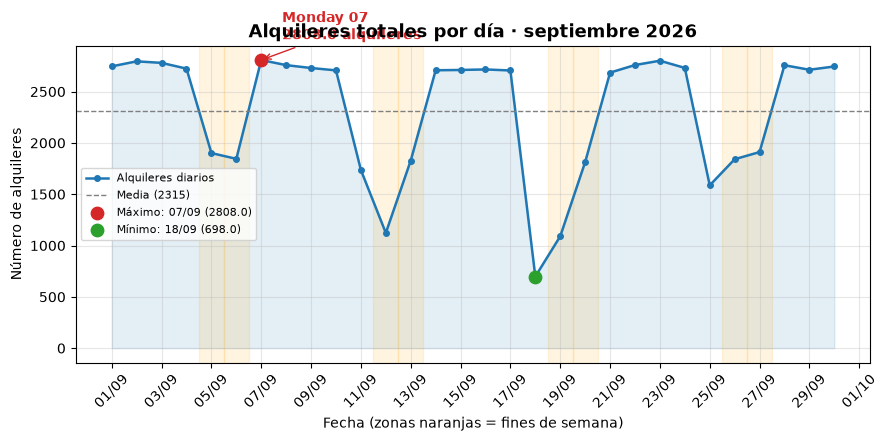

Día que destaca: 2026-09-07 con 2808.0 alquileres


In [37]:
# Reto 1 · El mes día a día
usage_hourly["timestamp"] = pd.to_datetime(usage_hourly["timestamp"])
daily = usage_hourly.groupby(usage_hourly["timestamp"].dt.normalize())["rentals"].sum()

pico = daily.idxmax()
valle = daily.idxmin()
media = daily.mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(daily.index, daily.values, marker="o", markersize=4, linewidth=1.8, color="tab:blue", label="Alquileres diarios")
ax.fill_between(daily.index, daily.values, alpha=0.12, color="tab:blue")
ax.axhline(media, color="gray", linestyle="--", linewidth=1, label=f"Media ({media:.0f})")

# Resaltar el día que destaca (máximo) y el mínimo
ax.scatter([pico], [daily[pico]], color="tab:red", s=80, zorder=3, label=f"Máximo: {pico:%d/%m} ({daily[pico]})")
ax.scatter([valle], [daily[valle]], color="tab:green", s=80, zorder=3, label=f"Mínimo: {valle:%d/%m} ({daily[valle]})")
ax.annotate(f"{pico:%A %d}\n{daily[pico]} alquileres",
            xy=(pico, daily[pico]), xytext=(15, 15), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="tab:red"), color="tab:red", fontweight="bold")

# Sombrear fines de semana
for dia in daily.index[daily.index.dayofweek >= 5]:
    ax.axvspan(dia - pd.Timedelta(hours=12), dia + pd.Timedelta(hours=12), color="orange", alpha=0.12)

ax.set_title("Alquileres totales por día · septiembre 2026", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha (zonas naranjas = fines de semana)")
ax.set_ylabel("Número de alquileres")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
ax.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=2))
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()

print("Día que destaca:", pico.date(), "con", daily.max(), "alquileres")

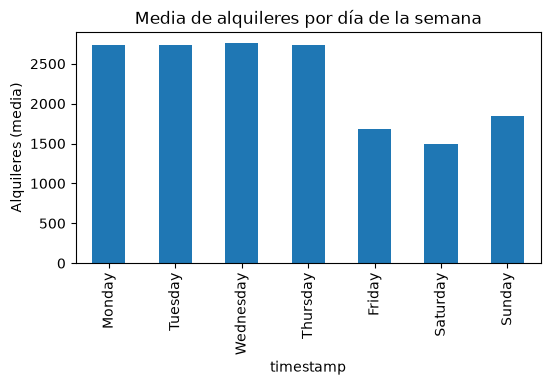

In [38]:
# Reto 2 · Día de la semana sin trampas: primero total por fecha, luego media por día de la semana
orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = (
    daily.groupby(daily.index.day_name()).mean().reindex(orden)
)

by_weekday.plot(kind="bar", figsize=(6, 3), title="Media de alquileres por día de la semana")
plt.ylabel("Alquileres (media)")
plt.show()

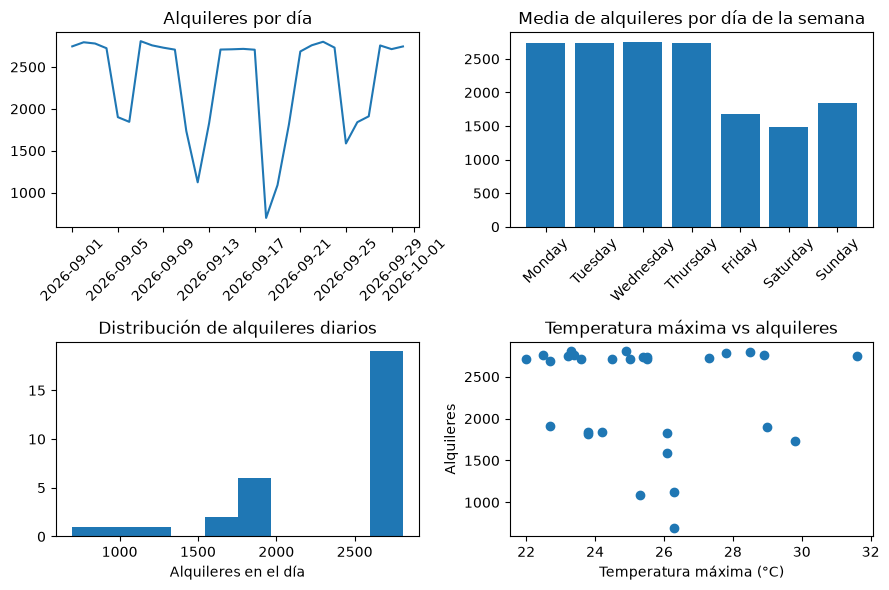

In [39]:
# Reto 3 · Cuatro gráficos
weather = weather_daily.assign(date=pd.to_datetime(weather_daily["date"]))
scatter_df = daily.rename_axis("date").rename("rentals").reset_index().merge(weather, on="date")

fig, axes = plt.subplots(2, 2, figsize=(9, 6))

axes[0, 0].plot(daily.index, daily.values)
axes[0, 0].set_title("Alquileres por día")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].bar(by_weekday.index, by_weekday.values)
axes[0, 1].set_title("Media de alquileres por día de la semana")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].hist(daily.values, bins=10)
axes[1, 0].set_title("Distribución de alquileres diarios")
axes[1, 0].set_xlabel("Alquileres en el día")

axes[1, 1].scatter(scatter_df["temp_max"], scatter_df["rentals"])
axes[1, 1].set_title("Temperatura máxima vs alquileres")
axes[1, 1].set_xlabel("Temperatura máxima (°C)")
axes[1, 1].set_ylabel("Alquileres")

fig.tight_layout()
plt.show()

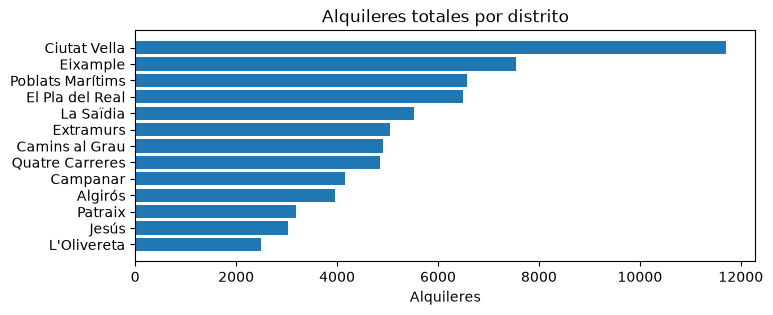

In [40]:
by_district = (
    usage_hourly.merge(stations[["station_id", "district"]], on="station_id")
    .groupby("district")["rentals"].sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(by_district.index, by_district.values)
ax.set_title("Alquileres totales por distrito")
ax.set_xlabel("Alquileres")
plt.show()


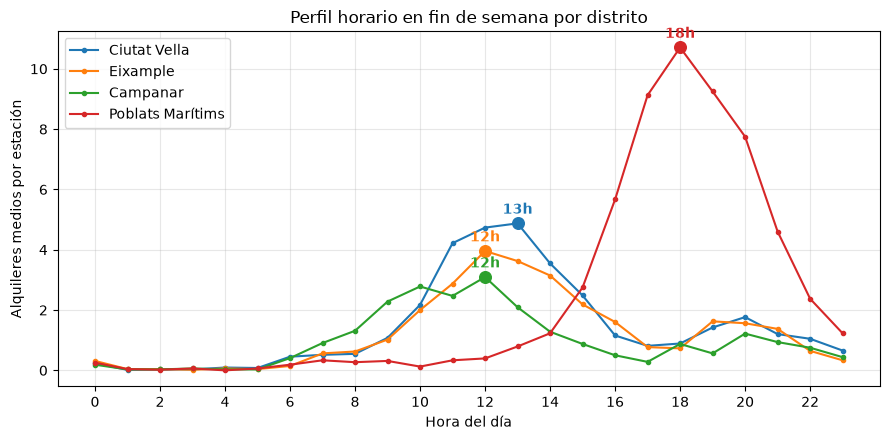

Hora del pico:
 district
Ciutat Vella        13
Eixample            12
Campanar            12
Poblats Marítims    18
dtype: int32


In [41]:
# Reto 4 · El fin de semana por zonas: perfil horario de cuatro distritos
distritos = ["Ciutat Vella", "Eixample", "Campanar", "Poblats Marítims"]
perfil = (
    usage[usage["weekend"] & usage["district"].isin(distritos)]
    .groupby(["district", "hour"])["rentals"].mean()
    .unstack(0)[distritos]
)

fig, ax = plt.subplots(figsize=(9, 4.5))
for distrito in distritos:
    linea, = ax.plot(perfil.index, perfil[distrito], marker="o", markersize=3, label=distrito)
    pico = perfil[distrito].idxmax()
    ax.scatter([pico], [perfil[distrito].max()], color=linea.get_color(), s=70, zorder=3)
    ax.annotate(f"{pico}h", (pico, perfil[distrito].max()), xytext=(0, 7),
                textcoords="offset points", ha="center", color=linea.get_color(), fontweight="bold")

ax.set_title("Perfil horario en fin de semana por distrito")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Alquileres medios por estación")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print("Hora del pico:\n", perfil.idxmax())

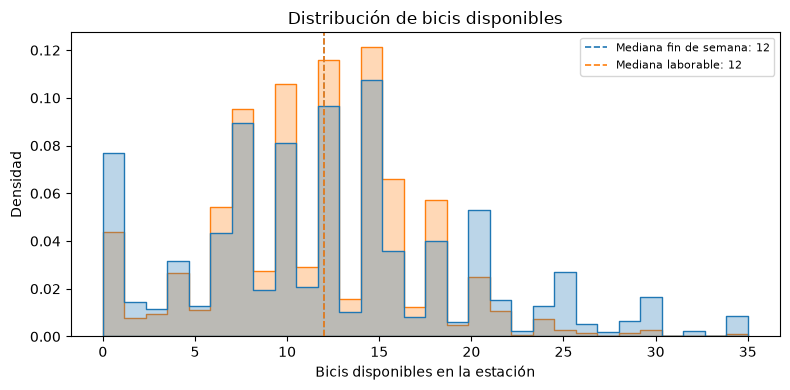

tipo
Fin de semana    12.0
Laborable        12.0
Name: bikes_available, dtype: float64


In [42]:
# Reto 5 · Bicis disponibles: laborables vs fines de semana
bicis = usage.dropna(subset=["bikes_available"]).copy()
bicis["tipo"] = np.where(bicis["weekend"], "Fin de semana", "Laborable")
medianas = bicis.groupby("tipo")["bikes_available"].median()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=bicis, x="bikes_available", hue="tipo", bins=30, stat="density",
             common_norm=False, element="step", alpha=0.3, ax=ax)
for tipo, mediana in medianas.items():
    ax.axvline(mediana, linestyle="--", linewidth=1.2, color="tab:orange" if tipo == "Laborable" else "tab:blue",
               label=f"Mediana {tipo.lower()}: {mediana:.0f}")
ax.set_title("Distribución de bicis disponibles")
ax.set_xlabel("Bicis disponibles en la estación")
ax.set_ylabel("Densidad")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

print(medianas)

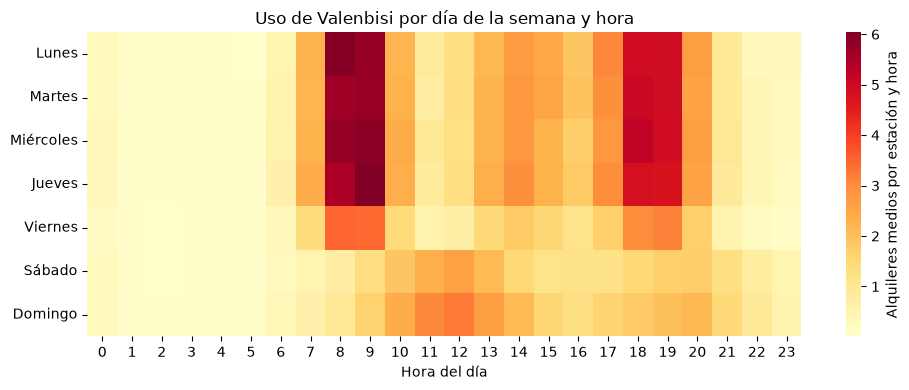

In [43]:
# Reto 6 · ¿Cuándo se usa Valenbisi? Día de la semana x hora
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
heat = usage.pivot_table(index="weekday", columns="hour", values="rentals", aggfunc="mean")
heat.index = dias

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Alquileres medios por estación y hora"}, ax=ax)
ax.set_title("Uso de Valenbisi por día de la semana y hora")
ax.set_xlabel("Hora del día")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

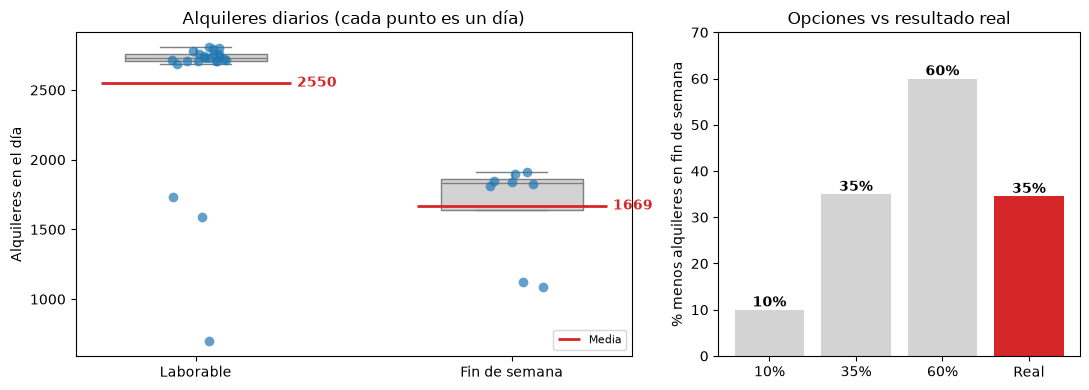

Media diaria: laborable 2550 · fin de semana 1669 → 34.6% menos


In [44]:
# EDA 1 · ¿Cuántos alquileres menos hay en fin de semana? ¿10%, 35% o 60%?
daily_df = daily.rename("rentals").rename_axis("date").reset_index()
daily_df["tipo"] = np.where(daily_df["date"].dt.dayofweek >= 5, "Fin de semana", "Laborable")
orden_tipo = ["Laborable", "Fin de semana"]

medias = daily_df.groupby("tipo")["rentals"].mean()
menos = (1 - medias["Fin de semana"] / medias["Laborable"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1.3]})

sns.boxplot(data=daily_df, x="tipo", y="rentals", order=orden_tipo, width=0.45, color="lightgray", fliersize=0, ax=axes[0])
sns.stripplot(data=daily_df, x="tipo", y="rentals", order=orden_tipo, color="tab:blue", alpha=0.7, s=7, ax=axes[0])
for i, tipo in enumerate(orden_tipo):
    axes[0].hlines(medias[tipo], i - 0.3, i + 0.3, color="tab:red", linewidth=2, label="Media" if i == 0 else None)
    axes[0].text(i + 0.32, medias[tipo], f"{medias[tipo]:.0f}", color="tab:red", va="center", fontweight="bold")
axes[0].set_title("Alquileres diarios (cada punto es un día)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Alquileres en el día")
axes[0].legend(loc="lower right", fontsize=8)

opciones = ["10%", "35%", "60%", "Real"]
barras = axes[1].bar(opciones, [10, 35, 60, menos], color=["lightgray", "lightgray", "lightgray", "tab:red"])
axes[1].bar_label(barras, fmt="%.0f%%", fontweight="bold")
axes[1].set_ylim(0, 70)
axes[1].set_ylabel("% menos alquileres en fin de semana")
axes[1].set_title("Opciones vs resultado real")
fig.tight_layout()
plt.show()

print(f"Media diaria: laborable {medias['Laborable']:.0f} · fin de semana {medias['Fin de semana']:.0f} → {menos:.1f}% menos")

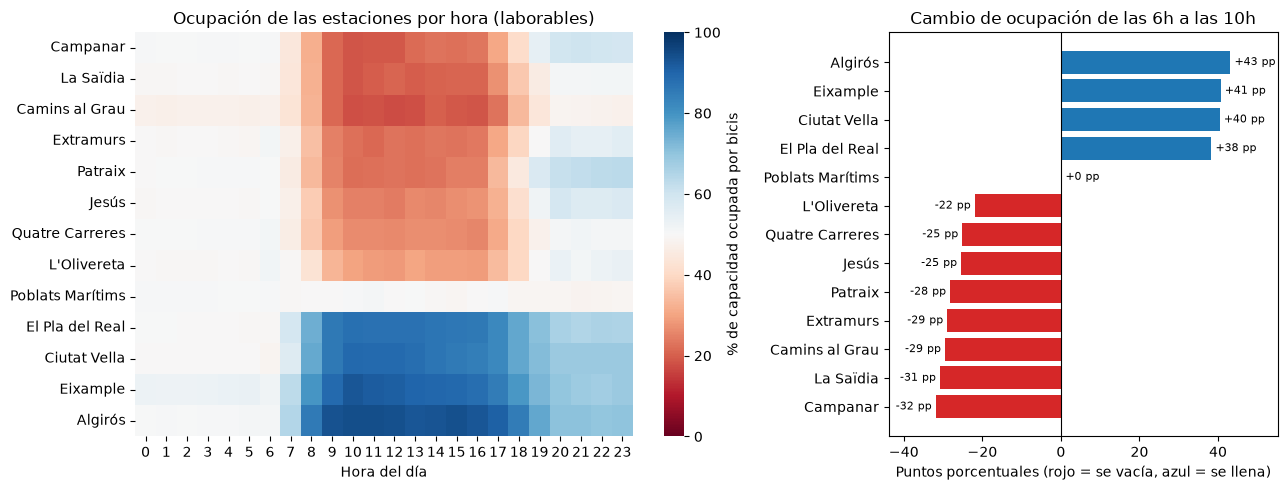

% de horas (7h-10h) con 0-1 bicis por estación:
district
Campanar            24.1
La Saïdia           21.6
Extramurs           18.2
Camins al Grau      16.5
Patraix             14.8
L'Olivereta          9.8
Quatre Carreres      9.5
Jesús                8.7
Poblats Marítims     2.1
Algirós              0.0
Ciutat Vella         0.0
Eixample             0.0
El Pla del Real      0.0


In [45]:
# EDA 2 · Desequilibrio: ¿qué distritos se vacían más por la mañana? (solo laborables)
lab = usage[~usage["weekend"]].merge(stations[["station_id", "capacity"]], on="station_id")
lab["ocupacion"] = lab["bikes_available"] / lab["capacity"] * 100   # % de la capacidad con bici

ocup = lab.groupby(["district", "hour"])["ocupacion"].mean().unstack()
cambio = (ocup[10] - ocup[6]).sort_values()                          # de las 6h a las 10h
vacias = lab[lab["hour"].between(7, 10)].assign(vacia=lambda d: d["bikes_available"] <= 1).groupby("district")["vacia"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})

sns.heatmap(ocup.loc[cambio.index], cmap="RdBu", center=50, vmin=0, vmax=100,
            cbar_kws={"label": "% de capacidad ocupada por bicis"}, ax=axes[0])
axes[0].set_title("Ocupación de las estaciones por hora (laborables)")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("")

colores = ["tab:red" if v < 0 else "tab:blue" for v in cambio.values]
barras = axes[1].barh(cambio.index, cambio.values, color=colores)
axes[1].bar_label(barras, fmt="%+.0f pp", padding=3, fontsize=8)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Cambio de ocupación de las 6h a las 10h")
axes[1].set_xlabel("Puntos porcentuales (rojo = se vacía, azul = se llena)")
axes[1].set_xlim(cambio.min() - 12, cambio.max() + 12)
fig.tight_layout()
plt.show()

print("% de horas (7h-10h) con 0-1 bicis por estación:")
print(vacias.sort_values(ascending=False).round(1).to_string())

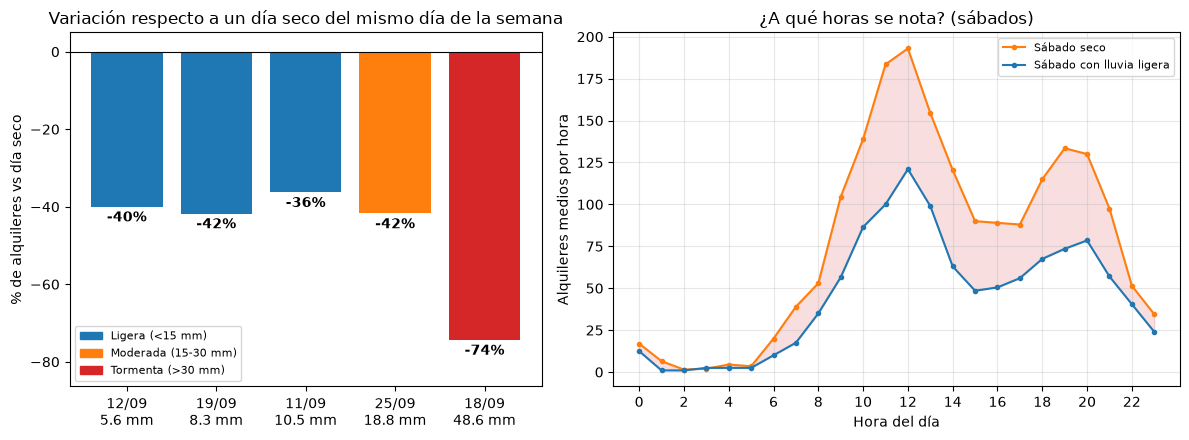

Lluvia ligera (3 días): -39% de media


In [46]:
# EDA 3 · Lluvia: ¿cuánto baja el uso en un día de lluvia ligera?
w = weather_daily.assign(date=pd.to_datetime(weather_daily["date"]))[["date", "rain_mm"]]
dd = daily.rename("rentals").rename_axis("date").reset_index().merge(w, on="date")
dd["dow"] = dd["date"].dt.dayofweek

# Referencia justa: media de los días secos del mismo día de la semana
base = dd[dd["rain_mm"] == 0].groupby("dow")["rentals"].mean()
lluvia = dd[dd["rain_mm"] > 0].copy()
lluvia["cambio"] = (lluvia["rentals"] / lluvia["dow"].map(base) - 1) * 100
lluvia["intensidad"] = pd.cut(lluvia["rain_mm"], [0, 15, 30, np.inf],
                              labels=["Ligera (<15 mm)", "Moderada (15-30 mm)", "Tormenta (>30 mm)"])
colores = {"Ligera (<15 mm)": "tab:blue", "Moderada (15-30 mm)": "tab:orange", "Tormenta (>30 mm)": "tab:red"}
lluvia = lluvia.sort_values("rain_mm")

# Perfil horario de los sábados: secos vs lluvia ligera
por_hora = usage.groupby([usage["timestamp"].dt.normalize(), "hour"])["rentals"].sum().reset_index()
por_hora = por_hora.rename(columns={"timestamp": "date"}).merge(dd[["date", "dow", "rain_mm"]], on="date")
sabados = por_hora[por_hora["dow"] == 5]
sab_seco = sabados[sabados["rain_mm"] == 0].groupby("hour")["rentals"].mean()
sab_lluvia = sabados[(sabados["rain_mm"] > 0) & (sabados["rain_mm"] < 15)].groupby("hour")["rentals"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})

etiquetas = [f"{f:%d/%m}\n{mm:g} mm" for f, mm in zip(lluvia["date"], lluvia["rain_mm"])]
barras = axes[0].bar(etiquetas, lluvia["cambio"], color=lluvia["intensidad"].map(colores))
axes[0].bar_label(barras, fmt="%.0f%%", fontweight="bold", padding=3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylim(min(lluvia["cambio"]) - 12, 5)
axes[0].set_title("Variación respecto a un día seco del mismo día de la semana")
axes[0].set_ylabel("% de alquileres vs día seco")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()], labels=list(colores), fontsize=8, loc="lower left")

axes[1].plot(sab_seco.index, sab_seco.values, marker="o", markersize=3, color="tab:orange", label="Sábado seco")
axes[1].plot(sab_lluvia.index, sab_lluvia.values, marker="o", markersize=3, color="tab:blue", label="Sábado con lluvia ligera")
axes[1].fill_between(sab_seco.index, sab_lluvia.values, sab_seco.values, color="tab:red", alpha=0.15)
axes[1].set_title("¿A qué horas se nota? (sábados)")
axes[1].set_xlabel("Hora del día")
axes[1].set_ylabel("Alquileres medios por hora")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

ligera = lluvia[lluvia["intensidad"] == "Ligera (<15 mm)"]
print(f"Lluvia ligera ({len(ligera)} días): {ligera['cambio'].mean():.0f}% de media")